# Input-convex neural networks (ICNN)

`jaxmat.nn` provides neural networks that are *convex in their inputs by
construction*, called **Input-Convex Neural Networks (ICNN)** {cite:p}`amos2017icnn`.
In constitutive modelling, such networks are particularly important
as convexity of a free energy implies material stability and convexity of a
dissipation potential is what makes the model thermodynamically admissible, etc.
Rather than discovering such convexity structure from data, imposing it beforehand
from the network architecture generally leads to much better extrapolation guarantees
and overall robustness to noise.

In this tutorial, we will explore the predictive capability of such networks and their use in
practice with `jaxmat`.

## A primer on convexity in $\mathbb{R}^n$

A function $f:\mathbb{R}^n\to\mathbb{R}$ is convex when

$$f\big(\theta \bx + (1-\theta) \by\big) \;\le\; \theta f(\bx) + (1-\theta) f(\by),
  \qquad \theta\in[0,1],$$

i.e. the chord between two points always lies above the function graph.
Equivalently, the epigraph $\{(\bx,t) : t \ge f(\bx)\}$ is a convex set.
Note that $f$ is *concave* iff $-f$ is convex. Affine functions are the only
functions which are both convex and concave.

Let us recall a few useful facts.

### Convexity in 1D
$f$ is convex on $\mathbb{R}^n$ if and only if $t \mapsto f((1-t)\bx + t \by)$
is convex for every line connecting $\bx,\by$. In the following, we will mostly tackle 1D
convex functions. Despite this simplicity, the 1D case is sufficiently representative
of the convex behavior in $\mathbb{R}^n$.

### Smooth vs non-smooth convex functions

$f$ is convex iff $\nabla^2 f(\bx) \succeq 0$ everywhere, and iff $f(\by) \ge f(\bx) +
 \nabla f(\bx)\cdot(\by-\bx)$,
that is every tangent plane always lies below the function graph. The second form still holds
without differentiability,
using the notions of subgradients. Note that if $\nabla^2 f(\bx) \succ 0$ we say that the function
is *strictly convex*.

### Convex-preserving calculus rules

It is important to have in mind that several operations naturally preserve convexity. Let us
consider that $f$ and $g_1,\ldots,g_k$ are convex functions. Then:
- non-negative linear combinations are convex; $\sum_{i=1}^k \alpha_ig_i(\bx)$ is convex for
$\alpha_i \geq 0$
- pointwise suprema: $\sup_{i}\{g_i(\bx)\}$ is convex
- pre-composition with an affine map:
   $f(\bA\bx+\bb)$ is convex for any $\bA,\bb$
- composition $f(g_1,\dots,g_k)(\bx)$ is convex when $f$ is convex and
   non-decreasing in each argument and every $g_i$ is convex.

The last rule is exactly what an ICNN is built from. Each layer computes
$\sigma(\bW^+ \bz + \bU \bx + \bb)$ where $\sigma$ is convex and non-decreasing
(e.g. `jax.nn.softplus``) and $\bW^+ \ge 0$: a convex non-decreasing function of a non-negative
combination of convex functions, plus an affine term. Convexity therefore
propagates through depth, whatever the weights take as values. Note that the
skip weights $\bU$ are *unconstrained*. The input $\bx$ enters affinely, so its sign
is irrelevant to convexity.

### Montonicity

Finally, *convexity* and  *monotonicity* are two unrelated properties.
$x \mapsto x^2$ is convex and not monotone and $x\mapsto x^3$ is monotone but non-convex.

Monotonicity is imposed in `jaxmat.nn.ICNN` by the `monotone` flag
which forces $\bU \ge 0$, per input. Some inputs may therefore have a monotone channel
while some may not while the overall function remains convex.

## Fitting convex functions with `jaxmat`

In the following, we demonstrate how to fit convex functions via an ICNN parametrization to given
 data. We first define a general `fit` function taking a model (typically an `ICNN` object) and
some data pairs $(x^{(k)},y^{(k)})$ looking for a best approximation $f(x^{(k)}) \approx y^{(k)}$.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import optax

from jaxmat.nn import ICNN, PolyhedralICNN, GaugeICNN

jax.config.update("jax_enable_x64", True)

C_TARGET = "#faa038"  # target curves: thick, muted
C_FREE = "#2563eb"  # unconstrained fit
C_MONO = "#e11d48"  # monotone-constrained fit


def fit(model, xs, ys, iters=5000, lr=5e-2, verbose=False):
    """Least-squares fit of a scalar network to samples."""
    opt = optax.adam(lr)
    state = opt.init(eqx.filter(model, eqx.is_inexact_array))

    @eqx.filter_jit
    def step(m, st):
        loss, grads = eqx.filter_value_and_grad(lambda mm: jnp.mean((jax.vmap(mm)(xs) - ys) ** 2))(
            m
        )
        upd, st = opt.update(grads, st, eqx.filter(m, eqx.is_inexact_array))
        return eqx.apply_updates(m, upd), st, loss

    for it in range(iters):
        model, state, loss = step(model, state)
        if verbose:
            print(f" Iter {it + 1} loss = {loss}")
    return model, loss


X = jnp.linspace(-2.0, 2.0, 200)[:, None]
X_data = X[30:170:2, :]
key = jax.random.PRNGKey(0)

### Fitting a target convex function

In this first example, data is generated from a ground truth convex function. The latter has
a deliberate kink induced by the $|x-1|$ term.
We fit a default ICNN (no monotonicity) with various depth to the data. We also plot the random
initialization for reference, showcasing the fact that the function is indeed
convex by construction.

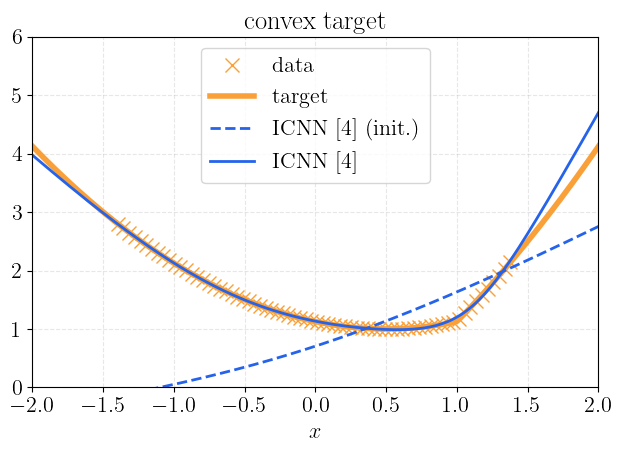

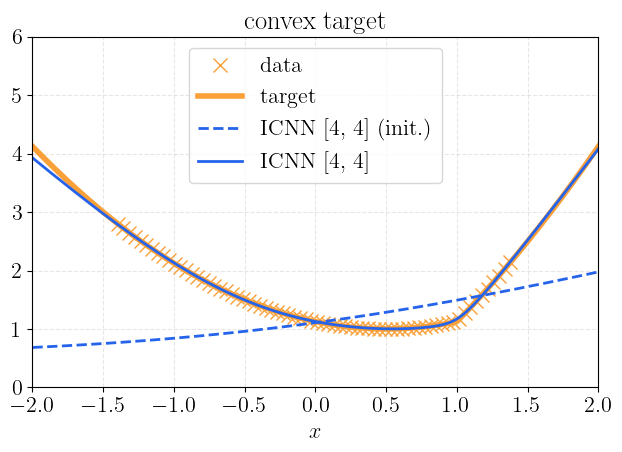

In [2]:
def convex_target(x):
    return jnp.squeeze(0.5 * (x + 0.5) ** 2 + jnp.abs(x - 1))


for hdim in ([4], [4, 4]):
    icnn = ICNN(1, hdim, key, monotone=False)
    m_convex, _ = fit(icnn, X_data, convex_target(X_data))

    fig, ax = plt.subplots()
    ax.plot(X_data, convex_target(X_data), "x", markersize=10, color=C_TARGET, label="data")
    ax.plot(X, convex_target(X), lw=4, color=C_TARGET, label="target")
    ax.plot(X, jax.vmap(icnn)(X), "--", lw=2.0, color=C_FREE, label=f"ICNN {hdim} (init.)")
    ax.plot(X, jax.vmap(m_convex)(X), "-", lw=2.0, color=C_FREE, label=f"ICNN {hdim}")
    ax.set_xlabel("$x$")
    ax.set_ylim(0, 6)
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_title("convex target")
    plt.tight_layout()
    plt.show()

We can see that both ICNN reproduce well the underlying data and extrapolate correctly
outside the training region in a convex manner. The deeper architecture has a slightly better fit.
Note however, that the kink is relatively difficult to recover precisely since the network is
smooth by default as it uses `softplus` activation functions. Changing to `relu` which is
non-smooth allows to better capture this kink.

An ICNN is a universal approximator *within* the convex functions, so on a convex target it
behaves like an ordinary network.

### Fitting a non-convex target function

In this second example, data is generated from a ground truth non-convex function. The latter is
deliberately built from an underlying convex function ($x^2$) superimposed with an oscillatory
function with decaying amplitude. This might be thought of an Ersatz of noise (the non-convex
 oscillatory part) on top of a hidden convex structure.

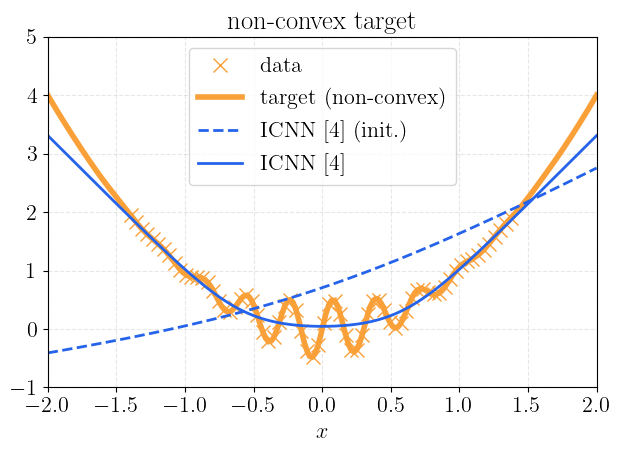

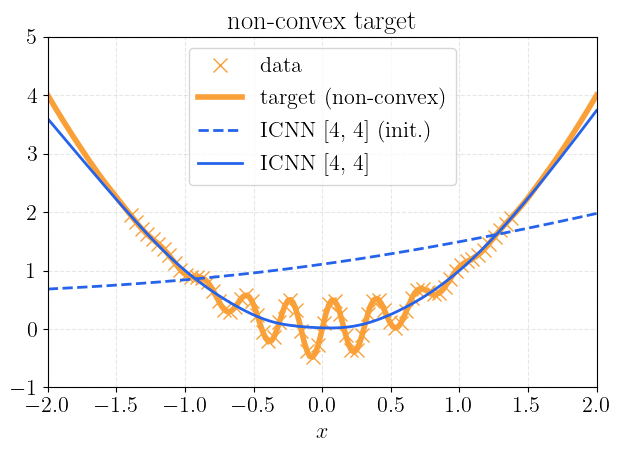

In [3]:
def wavy_target(X):
    return jnp.squeeze(X**2 + 0.5 * jnp.exp(-2 * X**2) * jnp.sin(20 * X))


for hdim in ([4], [4, 4]):
    icnn = ICNN(1, hdim, key, monotone=False)
    m_wavy, _ = fit(icnn, X_data, wavy_target(X_data))

    fig, ax = plt.subplots()
    ax.plot(X_data, wavy_target(X_data), "x", markersize=10, color=C_TARGET, label="data")
    ax.plot(X, wavy_target(X), lw=4, color=C_TARGET, label="target (non-convex)")
    ax.plot(X, jax.vmap(icnn)(X), "--", lw=2.0, color=C_FREE, label=f"ICNN {hdim} (init.)")
    ax.plot(X, jax.vmap(m_wavy)(X), "-", lw=2.0, color=C_FREE, label=f"ICNN {hdim} ")
    ax.set_xlabel("$x$")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_title("non-convex target")
    plt.tight_layout()
    plt.show()

We see that the network does not diverge, oscillate, or violate convexity. It
absorbs the part of the signal it is not allowed to represent and returns the
best convex approximation. In this case, the extrapolation behavior is well behaved
thanks to the convexity constraints. Note that this example also illustrates that we typically
do not need a larger number of parameters in such networks. Increasing the depth of the network
does not provide a much better accuracy since the underlying convex structure is already well
learned and the non convex part is simply filtered out by the model.

### Convex and monotone-convex networks

We recall that convexity comes from the non-negative hidden weights $\bW^+$;
monotonicity comes from the sign of the skip weights $\bU$, and the `monotone` flag sets it per
input.

Below, we take a target that is convex but non monotone and fit a standard ICNN and montone ICNN.

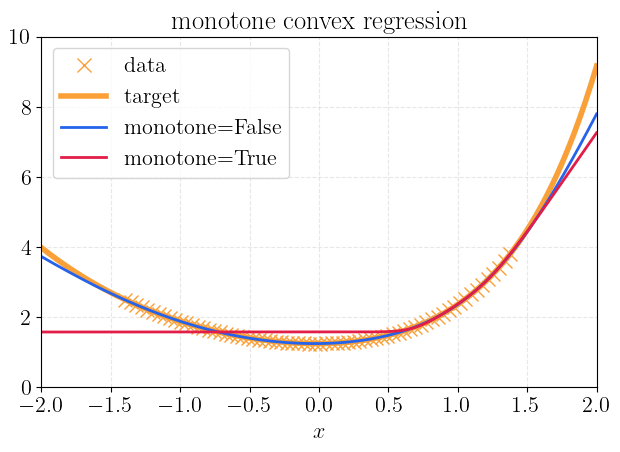

In [4]:
def target_fn(x):
    return jnp.squeeze(0.8 * jnp.exp(-0.8 * x) + 0.1 * jnp.exp(1.5 * (x + 1.0)))


icnn_free = ICNN(1, [8, 8], key, monotone=False)
m_free, _ = fit(icnn_free, X_data, target_fn(X_data))
icnn_mono = ICNN(1, [8, 8], key, monotone=True)
m_mono, _ = fit(icnn_mono, X_data, target_fn(X_data))

fig, ax = plt.subplots()
ax.plot(X_data, target_fn(X_data), "x", markersize=10, color=C_TARGET, label="data")
ax.plot(X, target_fn(X), lw=4, color=C_TARGET, label="target")
ax.plot(X, jax.vmap(m_free)(X), "-", lw=2.0, color=C_FREE, label="monotone=False")
ax.plot(X, jax.vmap(m_mono)(X), "-", lw=2.0, color=C_MONO, label="monotone=True")
ax.set_xlabel("$x$")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("monotone convex regression")
plt.tight_layout()
plt.show()

The unconstrained network tracks the target. The monotone one cannot.
Instead it uses a constant approximation in the decreasing part of the data and then increases
steeply once the target turns upwards and following data becomes admissible again.

## Gauge functions: convex *and* positively 1-homogeneous

We now turn to another class of convex functions, namely functions which are also
positively 1-homogeneous, i.e. such that $g(t\bx) = t g(\bx)$ for $t>0$. As a result,
we have that $g(0)=0$. In practice, we are often interested in functions which are also
positive $g(\bx)\geq 0$. In this case, we call them *gauge* functions or *Minkowski functionals*.
Their main property is that the unit level set $\{\bx \textrm{ s.t. } g(\bx) \leq 1\}$ uniquely
defines a convex body which contains the origin. Hence, gauge functions are another
way of describing such convex sets and are a natural object to represent plastic yield surfaces
for instance.

`jaxmat` provides a `PolyhedralICNN` which only learns polyhedral gauge functions (hence
polyhedral convex sets) and a more generic `GaugeICNN` based on the sublinear neural networks
developed in {cite:p}`martinet2026sublinear`which is a universal approximator of convex sets.

### Learning a polytope

We learn below the gauge of a random polytope from boundary points, asking only for
$g = 1$ on the boundary. Homogeneity extends that to the whole space, so a
single closed curve of samples determines $g$ everywhere.

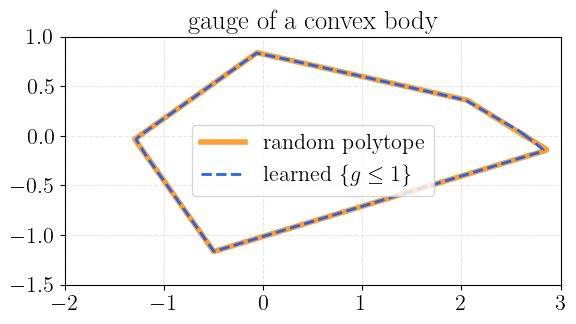

In [11]:
kA, kb = jax.random.split(jax.random.PRNGKey(7))
normals = jax.random.normal(kA, (9, 2))
normals = normals / jnp.linalg.norm(normals, axis=1, keepdims=True)
offsets = 0.7 + 0.9 * jax.random.uniform(kb, (9,))  # > 0, so the origin is inside

t = jnp.linspace(0, 2 * jnp.pi, 1000, endpoint=False)
dirs = jnp.stack([jnp.cos(t), jnp.sin(t)], 1)


def ray_cast(inside, n_iter=60):
    """Boundary of a star-shaped set, along each unit direction."""

    def one(u):
        def body(_, s):
            lo, hi = s
            m = 0.5 * (lo + hi)
            ok = inside(m * u)
            return (jnp.where(ok, m, lo), jnp.where(ok, hi, m))

        lo, hi = jax.lax.fori_loop(0, n_iter, body, (0.0, 20.0))
        return 0.5 * (lo + hi) * u

    return jax.vmap(one)(dirs)


target_body = ray_cast(lambda s: jnp.max(normals @ s - offsets) <= 0.0)

gauge, _ = fit(
    PolyhedralICNN(2, [8, 8], key),
    target_body,
    jnp.ones(target_body.shape[0]),
)
learned_body = ray_cast(lambda s: gauge(s) <= 1.0)


def close(P):
    return jnp.append(P, P[:1], 0)


fig, ax = plt.subplots()
ax.plot(*close(target_body).T, lw=4, color=C_TARGET, label="random polytope")
ax.plot(*close(learned_body).T, "--", lw=2, color=C_FREE, label=r"learned $\{g \leq 1\}$")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("gauge of a convex body")
plt.show()

The facets and corners are recovered, and homogeneity holds to machine
precision because it is structural rather than fitted. This is confirmed by plotting the
various level sets induced by the gauge function. They indeed correspond to a uniform dilation
of the convex body. This feature allows to easily model isotropic hardening in the case of plastic
yield surfaces.

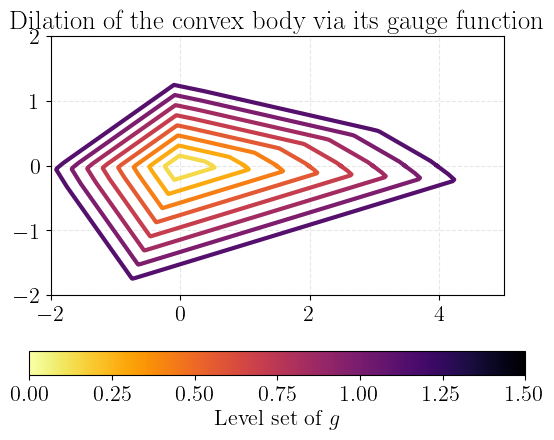

In [12]:
level_sets = jnp.linspace(0, 1.5, 9)[1:]
cmap = plt.colormaps.get_cmap("inferno_r")
norm = plt.Normalize(0, 1.5)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
fig, ax = plt.subplots()
for level in level_sets:
    body_ls = ray_cast(lambda s: gauge(s) <= level)
    plt.plot(*close(body_ls).T, "-", lw=3, color=cmap(level / 2))
ax.set_aspect("equal")
plt.colorbar(sm, ax=plt.gca(), label="Level set of $g$", orientation="horizontal")
ax.grid(alpha=0.3)
ax.set_title("Dilation of the convex body via its gauge function")
plt.show()

One limitation to be aware of: ReLU makes the learned body *polytopal*, so its
faces are exactly flat and the curvature of $g$ vanishes on them. To circumvent this,
we must use the more generic `GaugeICNN`.

A polyhedral gauge function can be written as $\max_k (w_k\cdot x)$. To obtain a non-polyhedral
gauge we replace the `max` by a smoothed maximum. Various possibilities exist but a common one
is the so-called `LogSumExp` defined as:

$$
\newcommand{\LSE}{\operatorname{LogSumExp}}
\LSE_{\beta}(\boldsymbol{x}) = \dfrac{1}{\beta}\log\left(\sum_k \exp(\beta x_k)\right)
$$
It is parametrized by a positive smoothing parameter `beta` and has the following property:

$$
\lim_{\beta\to \infty} \LSE_{\beta} = \max
$$

However, replacing the maximum by a `LogSumExp` smooths it but destroys homogeneity.  The
repair, following {cite:p}`martinet2026parametrizing`, is to evaluate the LSE on the normalised
direction and rescale it :

$$
    \gamma(\boldsymbol{x}) \;=\; \|\boldsymbol{x}\|
    \LSE_\beta\Big(\boldsymbol{W} \tfrac{\boldsymbol{x}}{\|\boldsymbol{x}\|}\Big).
$$
where $\boldsymbol{W}$ is a weight matrix containing the $\boldsymbol{w}_k$. In practice $\beta$
is trainable. It can be easily shown that $\gamma$ is positive, convex and 1-homogeneous, hence a gauge function.
As it contains the approximation space of polyhedra and polyhedra are dense, it is a universal approximator
of convex sets.

We first check that it can recover the previous polyhedron. Note that this network has a single layer.

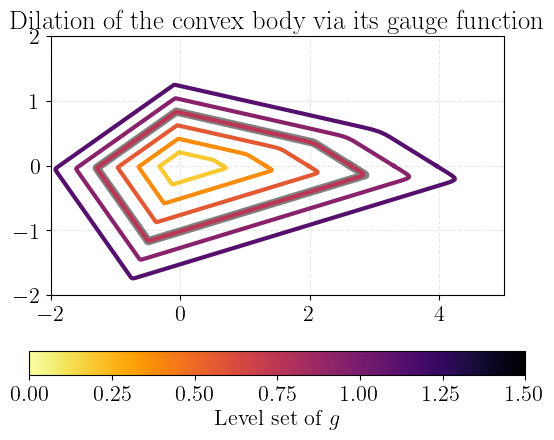

In [13]:
gauge, _ = fit(
    GaugeICNN(2, 16, key, rounding=False),
    target_body,
    jnp.ones(target_body.shape[0]),
)
learned_body = ray_cast(lambda s: gauge(s) <= 1.0)

level_sets = jnp.linspace(0, 1.5, 7)[1:]
cmap = plt.colormaps.get_cmap("inferno_r")
norm = plt.Normalize(0, 1.5)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
fig, ax = plt.subplots()
ax.plot(*close(target_body).T, lw=6, color="gray", label="random polytope")
for level in level_sets:
    body_ls = ray_cast(lambda s: gauge(s) <= level)
    plt.plot(*close(body_ls).T, "-", lw=3, color=cmap(level / 2))
ax.set_aspect("equal")
plt.colorbar(sm, ax=plt.gca(), label="Level set of $g$", orientation="horizontal")
ax.grid(alpha=0.3)
ax.set_title("Dilation of the convex body via its gauge function")
plt.show()

Let us now just understand the effect of the $\beta$ parameter.

In [14]:
print(f"Learned beta = {gauge.beta:.3f}")

Learned beta = 146.356


The learned value is relatively high, which means that the `LogSumExp` function is a good approximation to the `max` function, which is consistent with the fact that a polyhedron has been learned. We can indeed modify the value of $\beta$ to see its impact on the predictions.

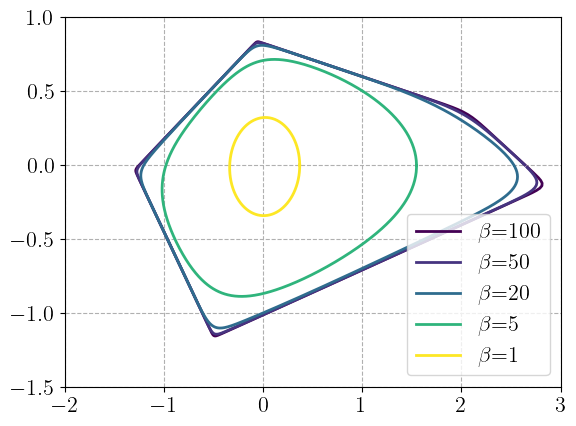

In [15]:
cmap2 = plt.colormaps.get_cmap("viridis_r")
beta_list = [100, 50, 20, 5, 1]
norm2 = mpl.colors.LogNorm(1, 100)
for beta in beta_list:
    new_gauge = eqx.tree_at(lambda m: m.beta_raw, gauge, jnp.log(beta))
    learned_body = ray_cast(lambda s: new_gauge(s) <= 1.0)
    plt.plot(
        learned_body[:, 0], learned_body[:, 1], color=cmap2(norm2(beta)), label=rf"$\beta$={beta}"
    )
plt.legend()
plt.show()

### Learning a generic convex set

We now use the `GaugeICNN` to learn a generic convex set made of the intersection of two random parabolas.

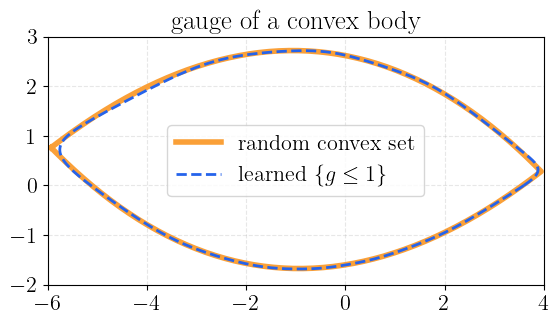

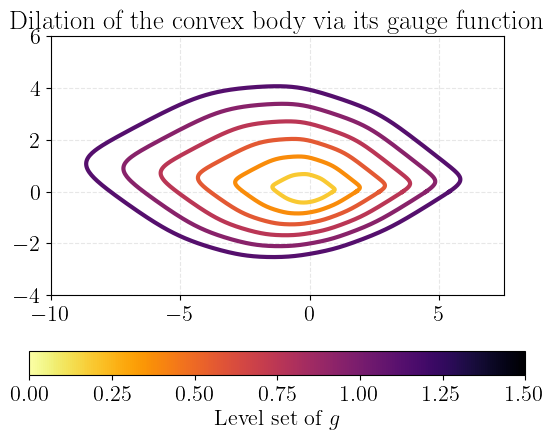

In [17]:
t = jnp.linspace(-1, 1, 100)
up = jnp.column_stack((t, 1 - t**2))
down = jnp.column_stack((-t, -1 + t**2))
key = jax.random.PRNGKey(0)
key1, key2 = jax.random.split(key)
A = jnp.diag(jnp.asarray([4, 1])) + 0.5 * jax.random.normal(key1, (2, 2))
b = 0.15 * jax.random.normal(key2, (2,))
target_body = (jnp.vstack((up, down)) + b) @ A

gauge, _ = fit(
    GaugeICNN(2, 16, key, rounding=False),
    target_body,
    jnp.ones(target_body.shape[0]),
)
learned_body = ray_cast(lambda s: gauge(s) <= 1.0)

fig, ax = plt.subplots()
ax.plot(*close(target_body).T, lw=4, color=C_TARGET, label="random convex set")
ax.plot(*close(learned_body).T, "--", lw=2, color=C_FREE, label=r"learned $\{g \leq 1\}$")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("gauge of a convex body")
plt.show()

fig, ax = plt.subplots()
for level in level_sets:
    body_ls = ray_cast(lambda s: gauge(s) <= level)
    plt.plot(*close(body_ls).T, "-", lw=3, color=cmap(level / 2))
ax.set_aspect("equal")
plt.colorbar(sm, ax=plt.gca(), label="Level set of $g$", orientation="horizontal")
ax.grid(alpha=0.3)
ax.set_title("Dilation of the convex body via its gauge function")
plt.show()

```{important}
As in the initial examples, the kinks are more difficult to reproduce accurately. This is due to the fact that we use a loss function
based on the L_2 distance of points on the convex set. To capture kinks, we should also add to the loss function an error on the normal vectors to the convex set which have strong variations in the kink regions.
```

# References

```{bibliography}
:filter: docname in docnames
```